<a href="https://colab.research.google.com/github/Kownlage/English/blob/main/bst_map_office_hours_lab_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BSTMap Lab: Office-Hours Booking

This notebook is **self-contained**. Upload this one `.ipynb` file to Google Colab or open it locally. You do **not** need the course repository inside the notebook runtime.

You can run all cells first to explore the sample dashboard, then complete the `BSTMap` class in Part 1. If you already implemented the same methods in `dsa/maps/bst_map.py`, copy your method bodies into the class cell here. Then implement two new BST queries, `floor_item` and `items_from`, using the search and in-order traversal ideas from the original map. Apply them in two booking functions, `can_book` and `next_free_slot`, and use the live app to explain the tree's behavior.

The app and sample data are provided. Keep the given `_Node` fields (`_key`, `_value`, `_left`, `_right`, `_parent`), `self._root`, and `self._size`: the tree visualization reads those names. The notebook uses only Python and optional `ipywidgets` for the app.

## Workflow

```text
[1] Run All to open the sample dashboard → [2] Implement BSTMap and the booking functions → [3] Rerun checks and use the app → [4] Answer eight tasks and submit
```

| Step | Student action | Done when |
|---|---|---|
| Setup | Run the small setup cell | No import or setup error |
| BSTMap | Complete or paste the ten original methods, then implement the new `floor_item` and `items_from` methods | The BST and nearby-query checks pass |
| Booking rules | Implement `can_book` and `next_free_slot` using `floor_item` and `items_from` | Both check cells pass |
| App | Run All to see the sample tree and schedule; compare load orders | Buttons that need unfinished methods log `Not implemented` until you complete them |
| Tasks | Write answers to all eight tasks; capture the requested tree/log evidence | Each answer is supported by your code and app output |

Run cells **from top to bottom** after opening the notebook in a new Colab session. The first time you use the app in Colab, its widget manager may need to initialize. If the app does not display, install `ipywidgets` in that runtime and rerun the app cell. No file path or Google Drive mount is required.
Run All can reach the dashboard before any TODO is complete. Check cells print **pending** for unfinished methods and **check failed** for other errors; only `all checks passed` means the solution passed. The sample preview uses the provided bookings for display. Once your map methods work, rerun their cells and click **Load sample** (or rerun the app cell) to use your `BSTMap`.


In [ ]:
# Setup: run once. This notebook does not import any course-repository files.
try:
    from google.colab import output as colab_output
except ImportError:
    pass
else:
    colab_output.enable_custom_widget_manager()

print("Notebook setup complete. Continue with Part 1 below.")

Notebook setup complete. Continue with Part 1 below.


## The booking rules

Office hours are **13:00 to 17:00**. A key is a meeting's start time as minutes since midnight (`14:00` is `840`). Its value is `(student_name, duration_minutes)`. The provided `to_minutes` and `fmt` helpers handle display; your two functions work with integers.

A meeting starting at `13:30` for 20 minutes occupies **[13:30, 13:50)**. The right endpoint is excluded: another meeting may start at `13:50`. Assume the existing schedule has valid, non-overlapping meetings. A new booking must have a positive duration and fit entirely inside office hours.

| Start | Student | Length | Occupied time |
|---|---|---:|---|
| 13:00 | Alice | 20 min | 13:00–13:20 |
| 13:30 | Ben | 20 min | 13:30–13:50 |
| 14:00 | Chloe | 30 min | 14:00–14:30 |
| 14:45 | Daniel | 15 min | 14:45–15:00 |
| 15:15 | Ella | 20 min | 15:15–15:35 |
| 16:00 | Finn | 30 min | 16:00–16:30 |

The sample is **inserted in a different order**. Iteration still shows it in time order. That is the BST property you will use.

| Python expression | Meaning |
|---|---|
| `schedule[t] = (name, minutes)` | Add or replace a booking starting at `t` |
| `schedule[t]` | Get that exact start time; missing keys raise `KeyError` |
| `t in schedule` | Check for an exact start time |
| `del schedule[t]` | Cancel that exact start time |
| `for t in schedule` | Visit all start times in increasing order |
| `len(schedule)` | Count bookings |

The original `bst_map.py` supports exact-key lookup and whole-tree iteration. Neither can jump directly to the booking near an arbitrary time. You will therefore **implement two new BST queries** in the class cell below:

| Query | Example on the sample | BST idea |
|---|---|---|
| `schedule.floor_item(14:10)` | `(14:00, ("Chloe", 30))` | Follow one search path and remember the most recent smaller key. |
| `schedule.items_from(14:10)` | Starts with `(14:45, ("Daniel", 15))` | Seek to the first key at or after the time, then continue in order. |

The examples use `14:10` as a time value; in code, pass `to_minutes("14:10")`. A `floor_item` result may be `None`, and `items_from` may be empty. Build `floor_item` from the one-path search idea in `_search`; build `items_from` from the in-order traversal idea in `__iter__`. In a BST with height `h`, each initial seek takes `O(h)`; `items_from` then yields `k` nearby bookings in `O(h + k)` total.

Your two **booking functions** must use only the public map interface, especially these two new methods: no `_root`, `_left`, `_right`, `sorted()`, full-tree `for ... in schedule` scans, or minute-by-minute search. In Part 1, you *will* use private node fields because you are implementing `BSTMap` itself. The tree is unbalanced, so `h` can be as large as `n`.

## Part 1 — Implement `BSTMap` in this notebook

The next cell includes the methods in `dsa/maps/bst_map.py` and two **new methods for you to implement** (`floor_item` and `items_from`). It is intentionally in this notebook so Colab students can run the lab without downloading or mounting the repository. If your course assignment is already complete, copy the method bodies you wrote into the matching methods below. Keep the class, method names, node fields, and parent links intact.

The BST rule: all keys to a node's left are smaller; all keys to its right are larger. `__iter__` must yield keys in increasing order. A two-child deletion copies the in-order predecessor (the largest key in the left subtree) before removing that predecessor's old node. Use loops for search, insertion, and iteration so a long one-sided tree does not hit Python's recursion limit.

**Implement the ten original methods:** `__init__`, `__len__`, `_search`, `__getitem__`, `__contains__`, `__setitem__`, `__delitem__`, `__iter__`, `_subtree_min`, and `_subtree_max`. You may paste the bodies you completed in `bst_map.py`. **Then implement the two new methods:** `floor_item` and `items_from`. The provided `_Node` and `is_empty` need no changes.

For `floor_item`, follow a BST search path and remember the best smaller key seen so far. For `items_from`, seek to the first eligible node before continuing in-order traversal; do not collect or sort all keys first. Handle an empty tree, an exact match, a key between stored starts, and a key after the last start.

In [ ]:
from typing import TypeVar, Generic, Iterator, Optional

K = TypeVar('K')
V = TypeVar('V')

class BSTMap(Generic[K, V]):
    """A map implemented as an unbalanced binary search tree.
    BST property: for every node, every key in its LEFT subtree is
    smaller than the node's key, and every key in its RIGHT subtree is
    larger. Every method below uses that one rule to decide which way
    to walk.
    """
    class _Node:
        """One node of the tree. Provided, nothing to edit here."""
        __slots__ = '_key', '_value', '_left', '_right', '_parent'
        def __init__(self, key, value, parent=None):
            self._key = key
            self._value = value
            self._left = None
            self._right = None
            self._parent = parent

    def __init__(self):
        """Create an empty map.
        Store the root node in `self._root` (None while the tree is
        empty) and the number of entries in `self._size`, starting at 0.
        """
        self._root = None
        self._size = 0

    def __len__(self) -> int:
        """Return the number of key-value pairs stored (self._size)."""
        return self._size

    def is_empty(self) -> bool:
        """Return True if the map contains no key-value pairs."""
        return len(self) == 0

    def _search(self, key: K, node) -> Optional['BSTMap._Node']:
        """Walk down from `node` looking for `key`.
        Return the node whose key equals `key`, or None once you fall
        off the bottom of the tree. Use a loop, not recursion.
        """
        current = node
        while current is not None:
            if key == current._key:
                return current
            elif key < current._key:
                current = current._left
            else:
                current = current._right
        return None

    def __getitem__(self, key: K) -> V:
        """Return the value stored for `key`.
        Raises:
            KeyError: if `key` is not present.
        """
        node = self._search(key, self._root)
        if node is None:
            raise KeyError(key)
        return node._value

    def __contains__(self, key: K) -> bool:
        """Return True if `key` is currently stored."""
        return self._search(key, self._root) is not None

    def __setitem__(self, key: K, value: V) -> None:
        """Associate `value` with `key`.
        Walk down from the root the same way `_search` does:
          * if you reach a node with this exact key, overwrite its value
            (the size does NOT change);
          * otherwise, when the next step would be None, attach a new
            node there as a leaf. Pass `parent=` so the new node knows
            its parent, and add 1 to `self._size`.
        Use a loop, not recursion: Task 8 builds a tree that is one
        long chain.
        """
        if self._root is None:
            self._root = self._Node(key, value)
            self._size = 1
            return

        current = self._root
        parent = None
        while current is not None:
            if key == current._key:
                current._value = value
                return
            parent = current
            if key < current._key:
                current = current._left
            else:
                current = current._right

        new_node = self._Node(key, value, parent)
        if key < parent._key:
            parent._left = new_node
        else:
            parent._right = new_node
        self._size += 1

    def __delitem__(self, key: K) -> None:
        """Remove `key` and its value.
        Three cases:
          * 0 children: unhook the node from its parent.
          * 1 child: the child moves up and takes the node's place.
          * 2 children: copy the key and value of the node's in-order
            predecessor (the largest key in its LEFT subtree, see
            `_subtree_max`) into the node, then remove the predecessor's
            node instead. The predecessor never has a right child, so
            removing it is always case 0 or case 1.
        When a child moves up, fix BOTH directions of the link: the
        parent's `_left` or `_right` must point to the child, and the
        child's `_parent` must point to the parent. If the removed node
        was the root, update `self._root`.
        Raises:
            KeyError: if `key` is not present.
        """
        node = self._search(key, self._root)
        if node is None:
            raise KeyError(key)

        # 2 children case: replace with in-order predecessor
        if node._left is not None and node._right is not None:
            succ = self._subtree_max(node._left)
            node._key = succ._key
            node._value = succ._value
            node = succ

        # 0 or 1 child case
        child = node._left if node._left is not None else node._right

        if child is not None:
            child._parent = node._parent

        if node._parent is None:
            self._root = child
        elif node is node._parent._left:
            node._parent._left = child
        else:
            node._parent._right = child

        self._size -= 1

    def __iter__(self) -> Iterator[K]:
        """Yield every key in increasing order (in-order traversal).
        Use an explicit stack instead of recursion: go left as far as
        you can, pushing every node on the way; pop one, yield its key,
        then continue the same way from its right child.
        """
        stack = []
        current = self._root
        while current is not None:
            stack.append(current)
            current = current._left

        while stack:
            node = stack.pop()
            yield node._key
            current = node._right
            while current is not None:
                stack.append(current)
                current = current._left

    def _subtree_min(self, node) -> 'BSTMap._Node':
        """Return the node with the smallest key in the subtree rooted
        at `node`."""
        walk = node
        while walk._left is not None:
            walk = walk._left
        return walk

    def _subtree_max(self, node) -> 'BSTMap._Node':
        """Return the node with the largest key in the subtree rooted
        at `node`."""
        walk = node
        while walk._right is not None:
            walk = walk._right
        return walk

    def floor_item(self, key: K) -> Optional[tuple[K, V]]:
        """Return the (key, value) with largest stored key <= key.
        Return None when every stored key is greater than key.
        Follow one BST search path rather than traversing every item.
        """
        current = self._root
        best = None
        while current is not None:
            if key == current._key:
                return (current._key, current._value)
            elif key < current._key:
                current = current._left
            else:
                best = (current._key, current._value)
                current = current._right
        return best

    def items_from(self, key: K) -> Iterator[tuple[K, V]]:
        """Yield (key, value) pairs in order, starting at the first key >= key.
        Skip earlier keys using BST links. Yield nothing if no key qualifies.
        """
        stack = []
        current = self._root
        while current is not None:
            if key <= current._key:
                stack.append(current)
                current = current._left
            else:
                current = current._right

        while stack:
            node = stack.pop()
            yield (node._key, node._value)
            curr = node._right
            while curr is not None:
                if key <= curr._key:
                    stack.append(curr)
                    curr = curr._left
                else:
                    curr = curr._right

## Sample schedule and time helpers

Run this provided cell after your `BSTMap` class cell. The six rows are listed in signup order, which differs from chronological order. The `load_sample()` helper creates a **fresh** schedule for each independent task.

In [ ]:
OPEN = 13 * 60
CLOSE = 17 * 60


def to_minutes(hhmm: str) -> int:
    hours, minutes = map(int, hhmm.split(":"))
    if not (0 <= hours <= 23 and 0 <= minutes <= 59):
        raise ValueError("Use a 24-hour time such as 13:40.")
    return hours * 60 + minutes


def fmt(minutes: int) -> str:
    return f"{minutes // 60:02d}:{minutes % 60:02d}"


# The order below is signup order, not chronological order.
SAMPLE_BOOKINGS = [
    ("14:00", "Chloe", 30),
    ("13:30", "Ben", 20),
    ("15:15", "Ella", 20),
    ("13:00", "Alice", 20),
    ("14:45", "Daniel", 15),
    ("16:00", "Finn", 30),
]


def load_sample(chronological: bool = False) -> BSTMap:
    '''Return a fresh schedule, optionally inserted by start time.'''
    rows = SAMPLE_BOOKINGS
    if chronological:
        rows = sorted(rows, key=lambda row: to_minutes(row[0]))
    schedule = BSTMap()
    for time_text, name, duration in rows:
        schedule[to_minutes(time_text)] = (name, duration)
    return schedule

In [ ]:
try:
    # Check Part 1 before continuing. This uses only the class in this notebook.
    empty = BSTMap()
    assert len(empty) == 0 and empty.is_empty()
    assert 10 not in empty
    assert empty.floor_item(10) is None
    assert list(empty.items_from(10)) == []
    try:
        empty[10]
    except KeyError:
        pass
    else:
        raise AssertionError("A missing key must raise KeyError")

    sample = load_sample()
    starts = [to_minutes(t) for t in ("13:00", "13:30", "14:00", "14:45", "15:15", "16:00")]
    assert len(sample) == 6
    assert list(sample) == starts
    assert sample[to_minutes("14:00")] == ("Chloe", 30)
    assert sample.floor_item(to_minutes("12:00")) is None
    assert sample.floor_item(to_minutes("14:10")) == (to_minutes("14:00"), ("Chloe", 30))
    assert sample.floor_item(to_minutes("14:00")) == (to_minutes("14:00"), ("Chloe", 30))
    assert [(fmt(t), name) for t, (name, _) in sample.items_from(to_minutes("14:10"))] == [
        ("14:45", "Daniel"), ("15:15", "Ella"), ("16:00", "Finn")
    ]
    assert list(sample.items_from(to_minutes("17:00"))) == []
    sample[to_minutes("14:00")] = ("Chloe", 25)
    assert len(sample) == 6 and sample[to_minutes("14:00")] == ("Chloe", 25)

    for removed, remaining in [
        ("13:00", ["13:30", "14:00", "14:45", "15:15", "16:00"]),
        ("13:30", ["13:00", "14:00", "14:45", "15:15", "16:00"]),
        ("14:00", ["13:00", "13:30", "14:45", "15:15", "16:00"]),
    ]:
        trial = load_sample()
        del trial[to_minutes(removed)]
        assert list(trial) == [to_minutes(t) for t in remaining]
        assert len(trial) == 5
        assert trial._root is None or trial._root._parent is None

    # The predecessor (13:30) has a left child, which must move up.
    two_child = load_sample()
    del two_child[to_minutes("14:00")]
    assert two_child._root._key == to_minutes("13:30")
    assert two_child._root._value == ("Ben", 20)
    assert two_child._root._left._key == to_minutes("13:00")
    assert two_child._root._left._parent is two_child._root
    assert two_child._root._right._left._key == to_minutes("14:45")

    print("BSTMap and nearby-booking queries: all checks passed")
except NotImplementedError as exc:
    print(f"BSTMap and nearby-booking queries: pending — {exc} is not implemented yet.")
except Exception as exc:
    print(f"BSTMap and nearby-booking queries: check failed — {type(exc).__name__}: {exc}")


BSTMap and nearby-booking queries: all checks passed


## Part 1 — Use the existing map

After implementing the map, rerun this cell and read its output. Before then, it reports which method is unfinished. Notice that `14:10 in schedule` is `False`: Chloe's meeting is in progress at 14:10, but **no meeting starts at exactly 14:10**. Map keys represent start times, not every minute occupied by a meeting. `floor_item(14:10)` finds Chloe's earlier start without scanning the schedule; `items_from(14:10)` begins with Daniel.

Then edit or rerun the last two lines to try another cancellation. The sample loader returns a fresh map each time.

In [ ]:
try:
    schedule = load_sample()
    print("Bookings:", len(schedule))
    print("Start times in order:", [fmt(t) for t in schedule])
    print("14:00 booking:", schedule[to_minutes("14:00")])
    print("Does a booking start at 14:10?", to_minutes("14:10") in schedule)
    previous = schedule.floor_item(to_minutes("14:10"))
    print("Latest start by 14:10:", (fmt(previous[0]), previous[1]) if previous else None)
    print("Later starts:", [fmt(t) for t, _ in schedule.items_from(to_minutes("14:10"))])

    practice = load_sample()
    del practice[to_minutes("14:00")]
    print("After canceling 14:00:", [fmt(t) for t in practice])
except NotImplementedError as exc:
    print(f"Part 1 map demo: pending — {exc} is not implemented yet.")
except Exception as exc:
    print(f"Part 1 map demo: check failed — {type(exc).__name__}: {exc}")


Bookings: 6
Start times in order: ['13:00', '13:30', '14:00', '14:45', '15:15', '16:00']
14:00 booking: ('Chloe', 30)
Does a booking start at 14:10? False
Latest start by 14:10: ('14:00', ('Chloe', 30))
Later starts: ['14:45', '15:15', '16:00']
After canceling 14:00: ['13:00', '13:30', '14:45', '15:15', '16:00']


## Part 2 — Write `can_book`

Complete the function below. It answers whether **[start, start + duration)** fits inside office hours without overlapping an existing booking. It must **not modify** `schedule`.

Because stored meetings do not overlap, **only two nearby bookings can conflict**: the latest start at or before `start`, and the first start at or after `start`. Use `schedule.floor_item(start)` for the first; use `next(schedule.items_from(start), None)` for the second. A pair is `(booked_start, (name, booked_duration))`. Check whether the previous meeting ends after `start`, and whether the next meeting starts before `start + duration`.

This is a real BST seek: on a tree of height `h`, the check takes `O(h)` regardless of how many earlier bookings exist. Examples: `13:40` for 10 minutes is refused; `13:50` for 10 minutes is allowed because touching endpoints do not overlap. Return `False` for a nonpositive duration or a meeting outside office hours.

In [ ]:
def can_book(schedule: BSTMap, start: int, duration: int) -> bool:
    '''Can [start, start + duration) be booked? Do not change schedule.'''
    # TODO: Check duration and office-hour boundaries.
    if duration <= 0 or start < OPEN or (start + duration) > CLOSE:
        return False
    # TODO: Check the meeting returned by floor_item(start), if any.
    prev = schedule.floor_item(start)
    if prev is not None:
        prev_start, (prev_name, prev_duration) = prev
        if prev_start + prev_duration > start:
            return False
    # TODO: Check only the first item returned by items_from(start), if any.
    next_item = next(schedule.items_from(start), None)
    if next_item is not None:
        next_start, (next_name, next_duration) = next_item
        if start + duration > next_start:
            return False

    return True

In [ ]:
try:
    # Run after completing can_book. Every check uses a fresh sample schedule.
    sample = load_sample()
    before = [(t, sample[t]) for t in sample]
    assert can_book(sample, to_minutes("13:40"), 10) is False  # overlaps Ben
    assert can_book(sample, to_minutes("13:50"), 10) is True   # touches Ben and Chloe
    assert can_book(sample, to_minutes("14:20"), 10) is False  # overlaps Chloe
    assert can_book(sample, to_minutes("14:30"), 15) is True   # fills gap exactly
    assert can_book(sample, to_minutes("16:30"), 30) is True   # ends at closing
    assert can_book(sample, to_minutes("16:40"), 30) is False  # past closing
    assert can_book(sample, to_minutes("12:50"), 10) is False  # before opening
    assert can_book(sample, to_minutes("13:20"), 0) is False   # invalid duration
    assert [(t, sample[t]) for t in sample] == before          # no mutation
    # A long prefix of earlier bookings must not be scanned via __iter__.
    class NoWholeTreeScan(BSTMap):
        def __iter__(self):
            raise AssertionError("Use nearby BST queries, not a full-tree scan")

    no_scan = NoWholeTreeScan()
    for time, booking in load_sample().items_from(OPEN):
        no_scan[time] = booking
    assert can_book(no_scan, to_minutes("16:30"), 30) is True
    print("can_book: all checks passed")
except NotImplementedError as exc:
    print(f"can_book: pending — {exc} is not implemented yet.")
except Exception as exc:
    print(f"can_book: check failed — {type(exc).__name__}: {exc}")


can_book: all checks passed


## Part 3 — Write `next_free_slot`

Complete the function below. Return the **earliest** start time at or after `after` that can hold a meeting of `duration` minutes. Return `None` if no slot fits before closing. The function must not change the schedule. Return `None` for a nonpositive duration.

Use `candidate` for the earliest start time that has not yet been ruled out:

1. Start at `max(after, OPEN)`. If even this time would finish after `CLOSE`, no later time can fit.
2. Ask `floor_item(candidate)` whether a meeting that started earlier is still in progress. If so, move `candidate` to its end.
3. Call `items_from(candidate)` **after that move**. It seeks to the first booking at or after the current candidate and yields later bookings in time order. Each pair already contains the duration.
4. Before each yielded booking, check whether `candidate + duration <= booked_start`. Equality means the new meeting ends exactly when the existing one begins, so it fits. Otherwise, move `candidate` to the yielded booking's end.
5. If no more bookings remain, return `candidate` only if it finishes by `CLOSE`.

Why is each move safe? When `candidate` is inside a booking, every earlier start before that booking ends would overlap it. When the gap before the next booking is too short for `duration`, starting later within the same gap cannot help. No possible earlier answer is skipped.

For the sample schedule, `after = 13:40` and `duration = 15` should return `14:30`. Trace the values of `candidate` and the bookings yielded by `items_from` in Task 6. If `k` bookings after the seek must be examined, the algorithm takes `O(h + k)` on a BST of height `h`; it does not scan earlier bookings or individual minutes.

In [ ]:
def next_free_slot(schedule: BSTMap, after: int, duration: int) -> int | None:
    '''Earliest available start >= after, or None. Do not change schedule.'''
    # TODO: Start at max(after, OPEN); return None if it cannot fit by CLOSE.
    if duration <= 0:
        return None
    candidate = max(after, OPEN)
    if candidate + duration > CLOSE:
        return None
    # TODO: Use floor_item(candidate) to escape a meeting already in progress.
    prev = schedule.floor_item(candidate)
    if prev is not None:
        prev_start, (_, prev_duration) = prev
        if prev_start + prev_duration > candidate:
            candidate = prev_start + prev_duration

    # TODO: Scan items_from(candidate), jumping over occupied bookings.
    for booked_start, (_, booked_duration) in schedule.items_from(candidate):
        if candidate + duration <= booked_start:
            if candidate + duration <= CLOSE:
                return candidate
            else:
                return None
        candidate = booked_start + booked_duration

    # TODO: Return the first fitting candidate, or None.
    if candidate + duration <= CLOSE:
        return candidate
    return None

In [ ]:
try:
    # Run after completing next_free_slot.
    sample = load_sample()
    before = [(t, sample[t]) for t in sample]
    assert next_free_slot(sample, to_minutes("13:40"), 10) == to_minutes("13:50")
    assert next_free_slot(sample, to_minutes("14:10"), 10) == to_minutes("14:30")
    assert next_free_slot(sample, to_minutes("13:40"), 15) == to_minutes("14:30")
    assert next_free_slot(sample, to_minutes("16:30"), 30) == to_minutes("16:30")
    assert next_free_slot(sample, to_minutes("16:45"), 30) is None
    assert next_free_slot(sample, to_minutes("12:00"), 10) == to_minutes("13:20")
    assert next_free_slot(sample, to_minutes("13:00"), 0) is None
    class NoScanForOpening(BSTMap):
        def __iter__(self):
            raise AssertionError("Use nearby BST queries, not a full-tree scan")

    no_scan_opening = NoScanForOpening()
    for time, booking in sample.items_from(OPEN):
        no_scan_opening[time] = booking
    assert next_free_slot(no_scan_opening, to_minutes("16:30"), 30) == to_minutes("16:30")
    assert [(t, sample[t]) for t in sample] == before  # no mutation

    del sample[to_minutes("14:00")]
    assert next_free_slot(sample, to_minutes("13:40"), 15) == to_minutes("13:50")
    print("next_free_slot: all checks passed")
except NotImplementedError as exc:
    print(f"next_free_slot: pending — {exc} is not implemented yet.")
except Exception as exc:
    print(f"next_free_slot: check failed — {type(exc).__name__}: {exc}")


next_free_slot: all checks passed


## Interactive booking app and BST visualization

The app uses the `BSTMap` class and the two booking functions **defined above in this notebook**. Each rounded node is a booking; each line is a parent–child link. A lookup marks its path in gray and numbers the visited nodes. The black node is the exact match. The schedule table shows keys in chronological order.

**Clear log** removes action history and highlighting without changing bookings. **Load sample** restores the sample schedule. Switch **Load order** and load again to compare the same bookings in two BST shapes. The interface has a high-contrast monochrome liquid-glass theme.

The app requires `ipywidgets`. In Colab, if its controls do not appear, run `%pip install ipywidgets` in a separate cell and rerun this app cell.
Run All shows the sample schedule and tree even while `BSTMap` methods are unfinished. **Load sample**, **Clear log**, and the load-order selector work in preview mode. Buttons requiring unfinished methods write `Not implemented: ...` in the action log. After editing and rerunning a method cell, click **Load sample** to refresh the app with the new class.


In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import HTML, display
except ImportError:
    print("Install ipywidgets in this notebook's kernel to use the optional app.")
else:
    from html import escape

    display(HTML("""
    <style>
    .bst-glass {
      --ink: #111; --muted: #444; --line: rgba(0,0,0,.42);
      color: var(--ink) !important;
      background:
        radial-gradient(52% 60% at 8% 5%, rgba(255,255,255,.98), transparent 80%),
        radial-gradient(50% 50% at 94% 95%, rgba(170,170,170,.34), transparent 80%),
        linear-gradient(145deg, #f3f3f3, #dedede 52%, #fafafa) !important;
      border: 1px solid rgba(255,255,255,.95);
      border-radius: 28px;
      padding: 20px;
      box-shadow: inset 0 1px 1px #fff, 0 22px 50px rgba(0,0,0,.18);
      font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Arial, sans-serif;
      backdrop-filter: blur(28px);
      -webkit-backdrop-filter: blur(28px);
    }
    .bst-glass .widget-label, .bst-glass label,
    .bst-glass .widget-html-content { color: #111 !important; }
    .bst-glass .widget-hbox { flex-wrap: wrap; }
    .bst-glass input, .bst-glass select {
      background: rgba(255,255,255,.86) !important;
      color: #111 !important;
      border: 1px solid rgba(0,0,0,.65) !important;
      border-radius: 14px !important;
      box-shadow: inset 0 1px 2px rgba(0,0,0,.10), 0 1px 0 #fff !important;
    }
    .bst-glass input:focus, .bst-glass select:focus {
      outline: 2px solid #111 !important;
      outline-offset: 1px;
    }
    .bst-glass button {
      background: linear-gradient(160deg, rgba(255,255,255,.96),
                   rgba(225,225,225,.78)) !important;
      color: #111 !important;
      border: 1px solid rgba(0,0,0,.6) !important;
      border-radius: 999px !important;
      font-weight: 700 !important;
      box-shadow: inset 0 1px 1px #fff, inset 0 -1px 1px rgba(0,0,0,.1),
                  0 5px 12px rgba(0,0,0,.16) !important;
      backdrop-filter: blur(14px);
      -webkit-backdrop-filter: blur(14px);
      margin: 3px !important;
    }
    .bst-glass button:hover, .bst-glass button:focus {
      background: #111 !important; color: #fff !important;
      border-color: #111 !important;
    }
    .bst-glass .bst-card {
      background: rgba(255,255,255,.68);
      border: 1px solid rgba(255,255,255,.96);
      border-radius: 22px;
      padding: 14px 16px;
      margin-top: 12px;
      box-shadow: inset 0 1px 1px #fff, 0 12px 28px rgba(0,0,0,.12);
      backdrop-filter: blur(22px);
      -webkit-backdrop-filter: blur(22px);
      color: #111;
    }
    .bst-glass .bst-card h3 { margin: 0 0 10px; color: #111; }
    .bst-glass .bst-chip {
      display: inline-block; border: 1px solid rgba(0,0,0,.55);
      background: rgba(255,255,255,.74); color: #111;
      border-radius: 999px; padding: 4px 10px; margin: 2px 6px 8px 0;
      font-size: 12px; font-weight: 650;
      box-shadow: inset 0 1px 0 #fff;
    }
    .bst-glass .bst-log-line {
      background: rgba(255,255,255,.65); color: #111;
      border: 1px solid rgba(0,0,0,.25); border-radius: 12px;
      padding: 7px 10px; margin: 5px 0;
    }
    .bst-glass .bst-tree-wrap {
      overflow-x: auto; border: 1px solid rgba(0,0,0,.25);
      background: rgba(255,255,255,.52); border-radius: 16px;
      padding: 10px;
    }
    .bst-glass table { border-collapse: collapse; width: 100%; color: #111; }
    .bst-glass th, .bst-glass td {
      border-bottom: 1px solid rgba(0,0,0,.3);
      padding: 7px 9px; text-align: left; color: #111;
    }
    .bst-glass th { background: rgba(255,255,255,.66); font-weight: 700; }
    </style>
    """))

    def preview_sample(chronological=False):
        """Build the provided tree for display without calling exercise methods."""
        rows = SAMPLE_BOOKINGS
        if chronological:
            rows = sorted(rows, key=lambda row: to_minutes(row[0]))
        preview = object.__new__(BSTMap)
        preview._root = None
        preview._size = 0
        for time_text, name, duration in rows:
            key = to_minutes(time_text)
            if preview._root is None:
                preview._root = BSTMap._Node(key, (name, duration))
            else:
                node = preview._root
                while True:
                    side = '_left' if key < node._key else '_right'
                    child = getattr(node, side)
                    if child is None:
                        setattr(node, side, BSTMap._Node(key, (name, duration), parent=node))
                        break
                    node = child
            preview._size += 1
        return preview

    def load_for_app(chronological=False):
        order = 'chronologically' if chronological else 'in signup order'
        try:
            return load_sample(chronological), f'Loaded {order}.'
        except Exception as exc:
            reason = f'{type(exc).__name__}: {exc}'
            return preview_sample(chronological), f'Sample preview loaded {order}; {reason}'

    initial_schedule, initial_message = load_for_app()
    live = {"schedule": initial_schedule, "log": [initial_message],
            "path": [], "selected": None}
    time_box = widgets.Text(value="13:40", description="Time:",
                            layout=widgets.Layout(width="190px"))
    name_box = widgets.Text(value="Your name", description="Name:",
                            layout=widgets.Layout(width="240px"))
    duration_box = widgets.Dropdown(options=[10, 15, 20, 30], value=15,
                                    description="Minutes:",
                                    layout=widgets.Layout(width="200px"))
    order_box = widgets.Dropdown(options=[("Signup order", False),
                                          ("Chronological", True)],
                                 value=False, description="Load order:",
                                 layout=widgets.Layout(width="260px"))
    action_log = widgets.HTML()
    table = widgets.HTML()
    tree = widgets.HTML()

    def snapshot(root):
        """Return nodes in key order with their depth; UI only."""
        nodes = []
        stack = []
        node, depth = root, 0
        while stack or node is not None:
            while node is not None:
                stack.append((node, depth))
                node, depth = node._left, depth + 1
            node, depth = stack.pop()
            nodes.append((node, depth))
            node, depth = node._right, depth + 1
        return nodes

    def search_path(root, target):
        """Show how an exact-key lookup descends; UI only."""
        path = []
        node = root
        while node is not None:
            path.append(node._key)
            if target == node._key:
                break
            node = node._left if target < node._key else node._right
        return path

    def tree_svg(nodes, path, selected):
        if not nodes:
            return '<div class="bst-tree-wrap">The tree is empty.</div>'
        col, row, node_w, node_h = 126, 94, 94, 50
        width = max(400, len(nodes) * col + 24)
        height = (max(depth for _, depth in nodes) + 1) * row + 26
        positions = {id(node): (74 + index * col, 46 + depth * row)
                     for index, (node, depth) in enumerate(nodes)}
        visit = {key: number for number, key in enumerate(path, 1)}
        parts = [
            f'<svg width="{width}" height="{height}" viewBox="0 0 {width} {height}" '
            'role="img" aria-label="Binary search tree of office-hours bookings" '
            'xmlns="http://www.w3.org/2000/svg">',
            '<defs><linearGradient id="bst-node-glass" x2="0" y2="1">'
            '<stop offset="0" stop-color="#fff" stop-opacity=".99"/>'
            '<stop offset="1" stop-color="#dedede" stop-opacity=".86"/>'
            '</linearGradient><linearGradient id="bst-node-visited" x2="0" y2="1">'
            '<stop offset="0" stop-color="#eee"/><stop offset="1" stop-color="#bdbdbd"/>'
            '</linearGradient><filter id="bst-node-shadow" x="-30%" y="-50%" '
            'width="160%" height="220%"><feDropShadow dx="0" dy="4" '
            'stdDeviation="4" flood-color="#000" flood-opacity=".22"/>'
            '</filter></defs>',
        ]
        for node, _ in nodes:
            x, y = positions[id(node)]
            for child in (node._left, node._right):
                if child is not None and id(child) in positions:
                    cx, cy = positions[id(child)]
                    active = node._key in visit and child._key in visit
                    edge_color = '#111' if active else '#555'
                    edge_width = 3 if active else 2
                    parts.append(
                        f'<line x1="{x}" y1="{y + node_h / 2}" '
                        f'x2="{cx}" y2="{cy - node_h / 2}" '
                        f'stroke="{edge_color}" '
                        f'stroke-width="{edge_width}"/>'
                    )
        for node, _ in nodes:
            x, y = positions[id(node)]
            picked = node._key == selected
            visited = node._key in visit
            fill = '#111' if picked else ('url(#bst-node-visited)' if visited
                                         else 'url(#bst-node-glass)')
            ink = '#fff' if picked else '#111'
            stroke = '#111' if picked or visited else '#555'
            name = str(node._value[0])
            parts.append(
                f'<g><title>{fmt(node._key)}: {escape(name)}</title>'
                f'<rect x="{x - node_w / 2}" y="{y - node_h / 2}" '
                f'width="{node_w}" height="{node_h}" rx="19" '
                f'fill="{fill}" stroke="{stroke}" stroke-width="2" '
                'filter="url(#bst-node-shadow)"/>'
                f'<text x="{x}" y="{y - 2}" text-anchor="middle" '
                f'font-family="Arial,sans-serif" font-size="14" font-weight="700" '
                f'fill="{ink}">{fmt(node._key)}</text>'
                f'<text x="{x}" y="{y + 14}" text-anchor="middle" '
                f'font-family="Arial,sans-serif" font-size="11" '
                f'fill="{ink}">{escape(name[:11])}</text></g>'
            )
            if visited:
                parts.append(
                    f'<circle cx="{x + node_w / 2 - 2}" cy="{y - node_h / 2 + 2}" '
                    'r="10" fill="#111" stroke="#fff" stroke-width="2"/>'
                    f'<text x="{x + node_w / 2 - 2}" y="{y - node_h / 2 + 6}" '
                    'text-anchor="middle" font-family="Arial,sans-serif" '
                    'font-size="10" font-weight="700" fill="#fff">'
                    f'{visit[node._key]}</text>'
                )
        parts.append('</svg>')
        return '<div class="bst-tree-wrap">' + ''.join(parts) + '</div>'

    def refresh():
        current = live['schedule']
        entries = ''.join('<div class="bst-log-line">' + escape(message) + '</div>'
                          for message in reversed(live['log'][-6:]))
        action_log.value = ('<div class="bst-card"><h3>Action log</h3>' + (entries or '<div class="bst-log-line">No actions yet.</div>') + '</div>')
        nodes = snapshot(current._root)
        rows = []
        for node, _ in nodes:
            start = node._key
            name, minutes = node._value
            rows.append(f'<tr><td>{fmt(start)}</td><td>{escape(str(name))}</td>'
                        f'<td>{minutes}</td><td>{fmt(start + minutes)}</td></tr>')
        table.value = ('<div class="bst-card"><h3>Schedule</h3><table>'
                       '<tr><th>Start</th><th>Student</th><th>Minutes</th><th>End</th></tr>'
                       + ''.join(rows) + '</table></div>')
        levels = max((depth for _, depth in nodes), default=-1) + 1
        chips = (f'<span class="bst-chip">{len(nodes)} bookings</span>'
                 f'<span class="bst-chip">{levels} levels</span>'
                 f'<span class="bst-chip">Fewest possible: {len(nodes).bit_length()} levels</span>')
        legend = ('<div style="font-size:12px;color:#333;margin-top:8px">'
                  'Gray = lookup path (numbers show visit order). '
                  'Black = selected booking. White = other bookings.</div>')
        tree.value = ('<div class="bst-card"><h3>Tree internals</h3>' + chips
                      + tree_svg(nodes, live['path'], live['selected']) + legend
                      + '</div>')

    def action(kind):
        if kind == 'clear':
            live['log'].clear()
            live['path'], live['selected'] = [], None
            refresh()
            return
        try:
            if kind == 'load':
                live['schedule'], message = load_for_app(order_box.value)
                live['path'], live['selected'] = [], None
            else:
                current = live['schedule']
                start = to_minutes(time_box.value.strip())
                live['path'], live['selected'] = [], None
                if kind == 'lookup':
                    live['path'] = search_path(current._root, start)
                    name, minutes = current[start]
                    live['selected'] = start
                    message = f'{fmt(start)}: {name}, {minutes} minutes.'
                elif kind == 'book':
                    if not name_box.value.strip():
                        raise ValueError('Enter a student name.')
                    if can_book(current, start, duration_box.value):
                        current[start] = (name_box.value.strip(), duration_box.value)
                        live['selected'] = start
                        message = f'Booked {name_box.value.strip()} at {fmt(start)}.'
                    else:
                        message = 'Booking refused: overlap or outside office hours.'
                elif kind == 'cancel':
                    del current[start]
                    message = f'Canceled the meeting starting at {fmt(start)}.'
                elif kind == 'opening':
                    found = next_free_slot(current, start, duration_box.value)
                    message = ('No opening fits before 17:00.' if found is None else
                               f'Earliest opening: {fmt(found)}.')
            live['log'].append(message)
        except KeyError:
            live['log'].append('No meeting starts at that exact time.')
        except NotImplementedError as exc:
            live['log'].append(f'Not implemented: {exc or "required function"}.')
        except (ValueError, TypeError) as exc:
            live['log'].append(str(exc))
        refresh()

    buttons = []
    for label, kind in [('Load sample', 'load'), ('Clear log', 'clear'),
                        ('Look up', 'lookup'),
                        ('Book', 'book'), ('Cancel', 'cancel'),
                        ('Find opening', 'opening')]:
        button = widgets.Button(description=label,
                                layout=widgets.Layout(width='132px'))
        button.on_click(lambda _, selected_kind=kind: action(selected_kind))
        buttons.append(button)

    app = widgets.VBox([
        widgets.HTML('<div style="font-size:25px;font-weight:750;color:#111">'
                     'Office-hours booking</div>'),
        widgets.HBox([order_box, buttons[0], buttons[1]]),
        widgets.HBox([time_box, name_box, duration_box]),
        widgets.HBox(buttons[2:]),
        action_log, table, tree,
    ])
    app.add_class('bst-glass')
    refresh()
    display(app)

## Lab tasks — record your observations

Complete the ten original BST methods, the two new BST queries, and the two booking functions; run all three check cells first. Use **Clear log** for a fresh action log; use **Load sample** between tasks that change the schedule. For every task, provide a short written answer and the requested screenshot(s). Insert screenshots below your answers in this notebook or submit clearly numbered image files with it. Screenshots support your explanation; they do not replace it.

### 1. Read the tree

**Screenshot:** Tree internals after loading in Signup order.
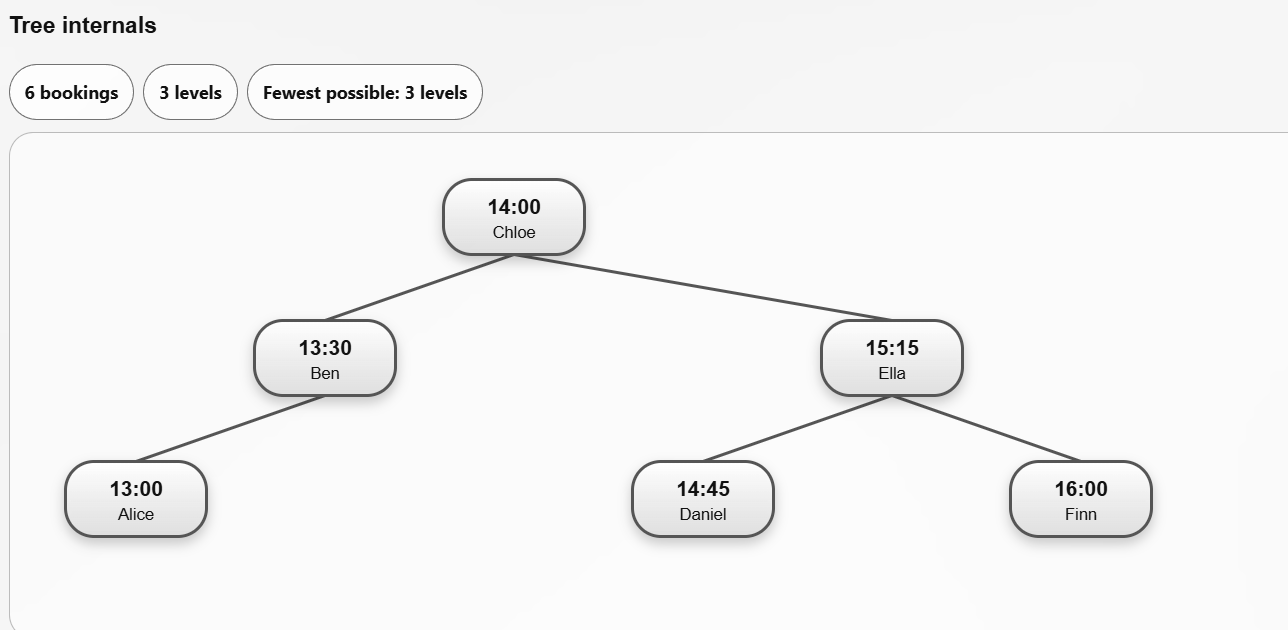

Load in **Signup order**. Which booking is at the root? How many levels does the tree have? What is the minimum possible number of levels for six nodes, and why?

**Your answer:**
Root: 14:00 (Chloe)

Levels: 3 (height $h = 2$)

Minimum possible number of levels for 6 nodes: 3.

Reason: For a binary tree of height $h$, the maximum number of nodes is given by $2^{h+1} - 1$.

A tree with 2 levels (height 1) can hold at most $2^2 - 1 = 3$ nodes. To accommodate 6 nodes, the tree requires at least 3 levels, since $3$ levels can hold up to $2^3 - 1 = 7$ nodes ($3 < 6 \le 7$).

### 2. Exact lookup versus a meeting in progress

**Screenshot:** Action log and numbered search path after both lookups.
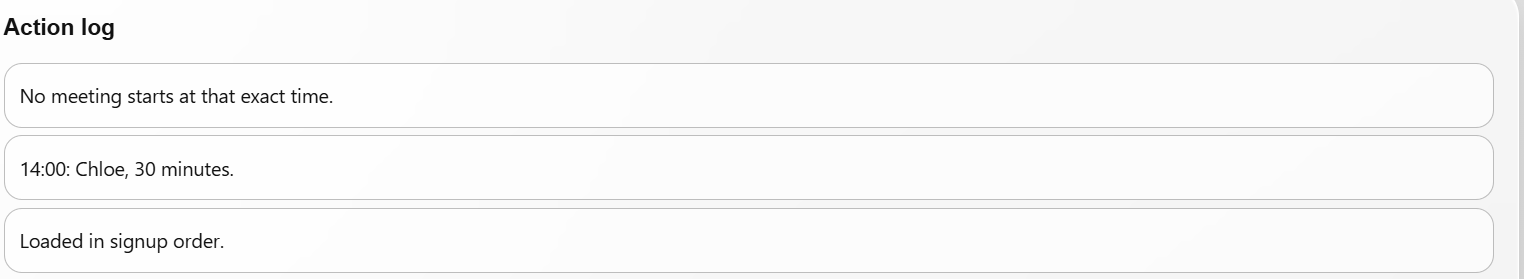

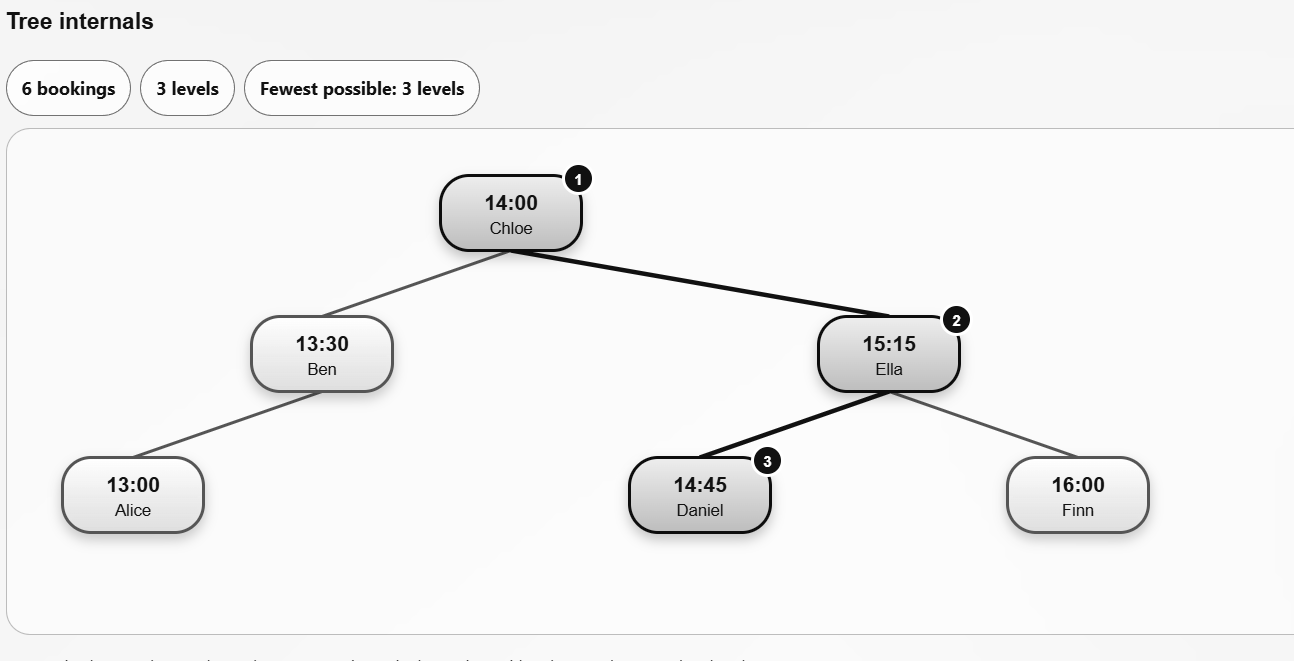

Look up `14:00`, then `14:10`. Which nodes does each lookup visit? Why does `14:10` report no start-time match even though Chloe is meeting at that time? What does `floor_item(14:10)` return?

**Your answer:**
Which nodes does each lookup visit?

Looking up 14:00 visits the root node directly (14:00 Chloe), finding an exact match in 1 step. Looking up 14:10 descends from the root (14:00) to the right child (14:45 Daniel) before falling off or stopping, as 14:10 is not in the tree.

Why does 14:10 report no start-time match even though Chloe is meeting at that time?

Map keys represent meeting start times (14:00), not every minute occupied by the meeting. Since no meeting starts at 14:10, an exact-key lookup fails.

What does floor_item(14:10) return?

It returns (840, ("Chloe", 30)) (i.e., 14:00 (Chloe, 30 min)), which is the largest stored key less than or equal to 14:10.

### 3. Chronological output

**Screenshot:** Schedule table showing all six bookings in time order.
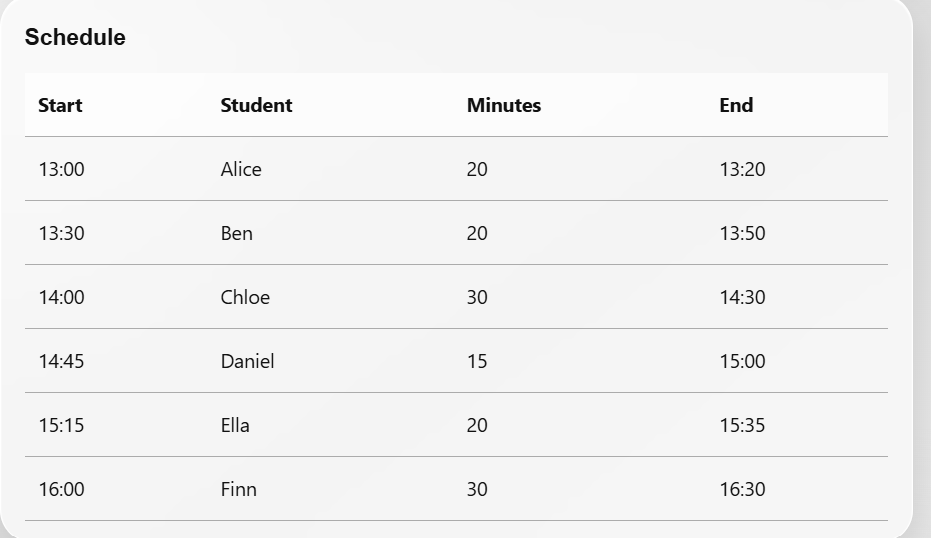

Read the schedule table or iterate through the map. List the start times in order. Why are they sorted when the bookings were inserted in a mixed order? For `items_from(14:10)`, which booking is yielded first, and why are earlier starts skipped?

**Your answer:**

Start times in order:13:00, 13:30, 14:00, 14:45, 15:15, 16:00.

Why are they sorted?：The bookings are automatically sorted because in-order traversal of a Binary Search Tree (BST) visits nodes from left to root to right, yielding keys in increasing order regardless of their insertion sequence.

items_from(14:10) behavior:
It yields 14:45 (Daniel) first. Earlier starts are skipped because the method uses BST links to descend directly to the first eligible node ($\ge 14:10$) without scanning the entire tree.

### 4. Three cancellation cases

**Screenshots:** Three separate tree views, one after each deletion from a freshly loaded sample.
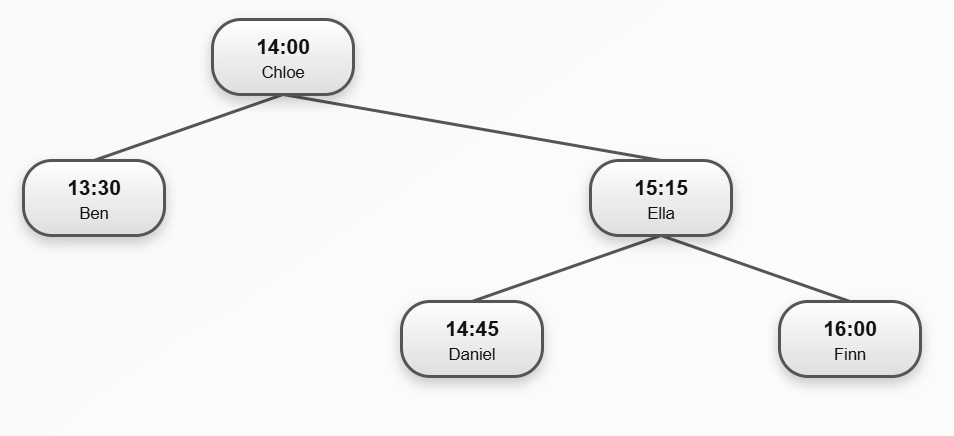

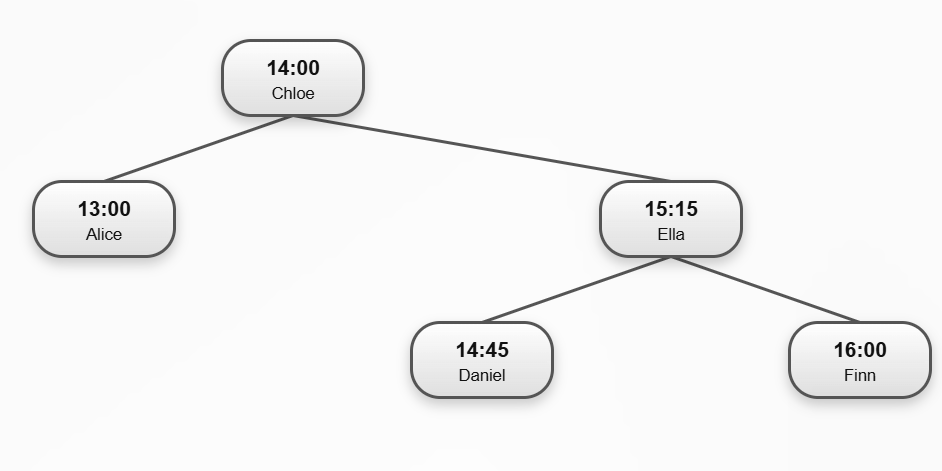

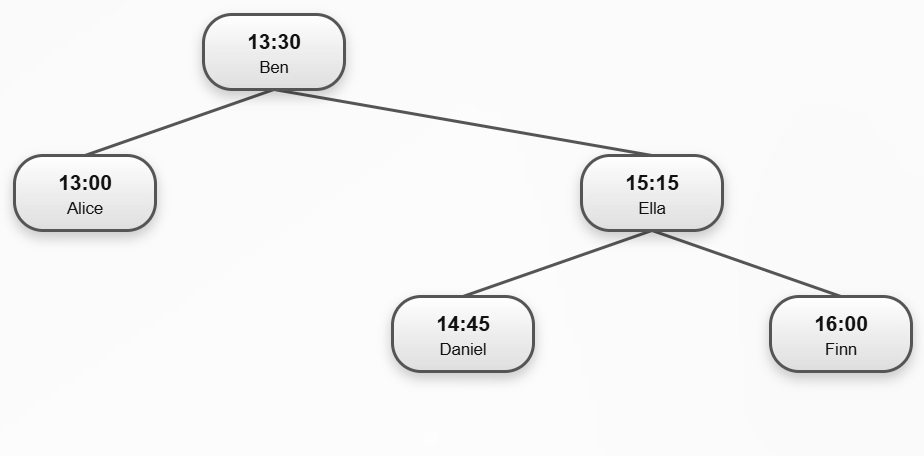


Reload before **each** case: cancel `13:00` (leaf), then reload and cancel `13:30` (one child), then reload and cancel `14:00` (two children). For each case, explain which link changes. After canceling `14:00`, which predecessor takes the root position, and how is its left child reattached?

**Your answer:**

Case 1: Deleting a leaf node (e.g., cancelling 13:00)

Link change: The parent's reference (_left or _right) pointing to the target node is set to None, unhooking the node from the tree.

Case 2: Deleting a node with one child (e.g., cancelling 13:30)

Link change: The target node's child moves up to take its place. The parent's _left or _right points directly to the child, and the child's _parent is updated to point to the new parent (or None if it becomes the root).

Case 3: Deleting a node with two children (e.g., cancelling 14:00)

Link change & Root replacement:

First, the in-order predecessor (the largest key in the left subtree, which is 13:30) has its key and value copied into the target node (14:00).

Then, the predecessor's old node (which has at most one child) is removed using Case 0 or Case 1, and its child is reattached upward to its parent's appropriate branch (_left or _right) with updated _parent pointers.


### 5. Reject or accept a request

**Screenshot:** Action log and schedule after trying all three requests; enter your name for the accepted booking.
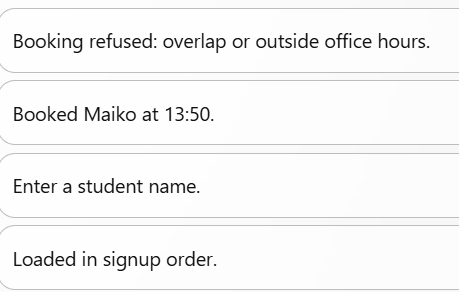

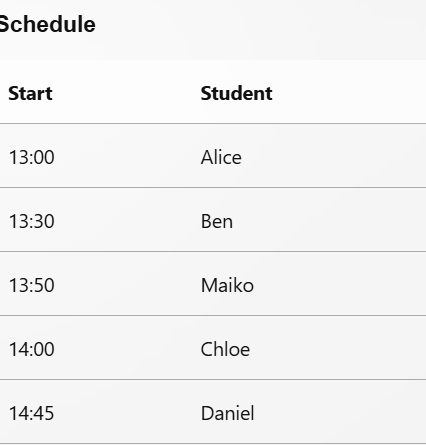

Reload. Use your `can_book` function to explain why `13:40` for 10 minutes is refused, `13:50` for 10 minutes is accepted, and `16:40` for 30 minutes is refused. Which nearby bookings does `can_book` check, and why can it ignore all others? Does it insert anything?

**Your answer:**
Why is 13:40 refused?:
It overlaps with Ben's existing booking (13:30–13:50), as checked by can_book using floor_item(13:40).

Why is 13:50 accepted?:
It fits exactly in the gap between Ben's booking ending at 13:50 and Chloe's meeting starting at 14:00 (touching endpoints do not overlap).

Why is 16:40 refused?:
The meeting would finish at 17:10, which exceeds the office-hours closing time (17:00).

Which nearby bookings are checked?:
Only the previous booking (floor_item) and the next booking (items_from) are checked to determine overlap, allowing $O(h)$ efficiency without scanning the entire tree. It does not mutate the schedule during the check.

### 6. Find the first opening

**Screenshot:** Action log showing the suggested opening.

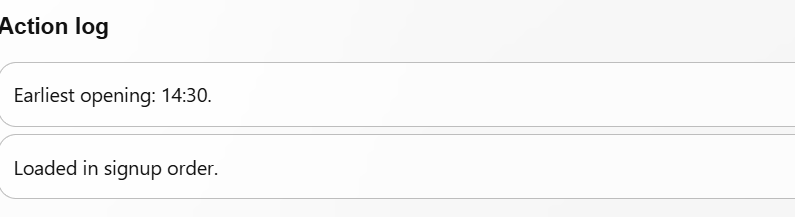

Reload the original sample first so the accepted `13:50` booking from Task 5 is removed. Then, from `13:40`, request 15 minutes. Give a short trace showing: (a) the result of `floor_item(13:40)`, (b) every value of `candidate`, (c) each booking yielded by `items_from`, and (d) the comparison that accepts or rejects each gap. Why is the answer `14:30` instead of `13:50`? Which earlier bookings does `items_from` avoid yielding, and might it still compare an earlier node while seeking?

**Your answer:**

(a) Result of floor_item(13:40):
Returns (13:30, ("Ben", 20)) because Ben's meeting ends at 13:50 (which is>13:40), causing candidate to jump to 13:50.

(b) Every value of candidate:
Starts at 13:40
→ updated to 13:50 (via floor_item)
→ checked against Ben's end time
→ moves to 14:00 (Chloe's start time)
→ checks gap (14:00 - 13:50 = 10 min < 15 min)
→ moves to 14:30 (Chloe's end time)
→ finds a valid slot at 14:30.

(c) Bookings yielded by items_from(candidate):
Yields 14:00 (Chloe, 30) and subsequent bookings.

(d) Comparison of each gap:
Compares candidate + duration <= booked_start; gaps before 14:30 are too short for 15 minutes, whereas the gap starting at 14:30 fits the request.

Why 14:30 instead of 13:50?
Although 13:50 is the earliest unoccupied minute, a 15-minute meeting starting there would finish at 14:05, overlapping with Chloe's meeting (14:00–14:30). Therefore, the algorithm skips to 14:30.

Efficiency and skipped nodes:
items_from avoids yielding earlier bookings (like Alice and Ben) by using BST structural links to descend directly to the first eligible node (
≥13:40). While seeking, it only inspects nodes along the search path (
𝑂
(
ℎ
)
), without scanning every minute or earlier independent branches.

### 7. Cancellation changes availability

**Screenshot:** Action log and tree after the cancellation and new suggestion.

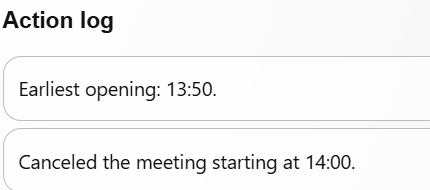

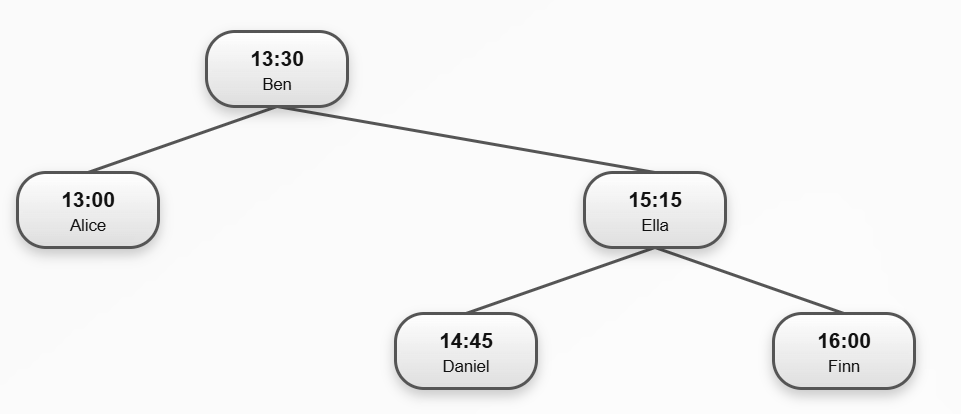


Keep the schedule from Task 6 (do not reload), cancel the `14:00` booking, then repeat the search from Task 6. What is the new first opening? Explain which gap became available.

**Your answer:**

New first opening:
13:50

Which gap became available:
Canceling Chloe's meeting (14:00–14:30) extended the available gap following Ben's meeting. Since Ben's booking ends at 13:50, and the next booking (Daniel) is now at 14:45, a 15-minute slot starting at 13:50 fits completely before any occupied time.

### 8. Same bookings, different tree

**Screenshot:** Tree internals after loading in Chronological order.


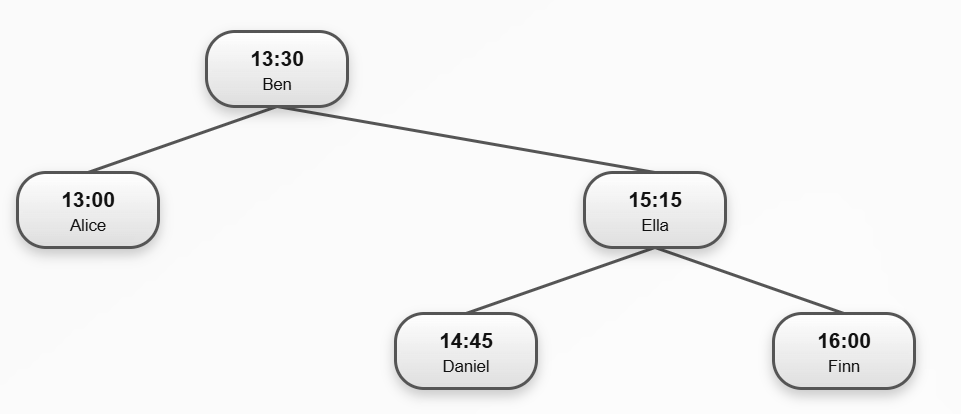


Reload in **Signup order** and note the number of levels. Reload in **Chronological** order. What shape appears, how many levels does it have, and what does that imply for a worst-case lookup and for `can_book` in this unbalanced BST?

**Your answer:**

What shape appears and levels:
When loaded in chronological order, the BST turns into a linear, one-sided chain (degenerate tree) extending entirely to the right. It has 6 levels (height $h = 5$).

Implications for worst-case lookup and can_book:
Because the tree is unbalanced and degenerates into a linked-list-like chain, the worst-case time complexity for lookups, floor_item, and items_from degrades from $O(\log n)$ to $O(n)$.Consequently, can_book and next_free_slot will require traversing up to $O(n)$ nodes in the worst case instead of $O(h)$, losing the performance advantage of a balanced search tree.

**Submit:** the completed notebook, passing checks, written answers to all eight tasks, and the requested screenshots.